In [1]:
import numpy as np
from scipy.special import jv, jn_zeros
from scipy.sparse.linalg import eigsh, ArpackNoConvergence
from scipy.linalg import eigh_tridiagonal
from scipy.sparse import diags, identity
from scipy.interpolate import interp1d, CubicSpline
from scipy.optimize import fsolve, brentq
from scipy.integrate import quad
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Solución de la ecuación de difusión para un coeficiente $D(z)$ variable

## Parámetros físicos

In [2]:
##############################################################################
# 1. Parámetros Físicos (en nanómetros)
##############################################################################
# Conversión: 1 m = 1e9 nm.
d = 15               # Profundidad del NV en nm
D0 = 2e6             # 2e-9 * 1e18     # 2e-9 m²/s -> 2e9 nm²/s
D_s = 2e4            # nm^2/s
R = 100*d             # 1e-6 m -> 1500 nm
delta = 2*d/3           # 1 nm (ancho de transición)
lambda_param = 0.75/d  # en nm⁻¹
n_modes_radial = 50  # Cantidad de modos de R(ρ)
m_max = 50           # Cantidad de modos de Z(z)
N_r = N_z = 85000    # Número de nodos en r y z
alpha_grid = 5.0     # Aglomeramiento de nodos cerca de z=0
varkappa = 0.0       # nm/s
L = 100*d             # nm
z_c = lambda_param*L  # altura crítica

## Malla adaptativa en $z$
Para el caso de la coordenada $z$, se opta por una malla que tenga una mayor concentración de nodos cerca de $z=0$ y que el espaciado entre estos aumente conforme $z>0$. Esto permite resolver los gradientes fuertes de $D(z)$ cerca de la superficie. Para hacer esto, se realiza una transformación hiperbólica para concentrar los nodos, como en la ecuación:
                
$$z_j=d+L\cdot \frac{\sinh{\left(\alpha_\mathrm{grid}\cdot\frac{j}{N_{z}-1}\right)}}{\sinh{\alpha_\mathrm{grid}}},\quad j\in\left[0,N_{z}-1\right]$$

Donde $\alpha_\mathrm{grid}\in\mathbb{N}$ es el parámetro de estiramiento, un factor que se encarga de controlar la densidad de nodos cerca de la superficie ($z\to0$), permitiendo una resolución espacial ajustada, $N_z$ es el número total de nodos y $L$ es la altura máxima en $z$.

De esta forma el espaciado entre nodos se calculará como:

$$h_j=z_j-z_{j-1},\,\forall\,j=1,2,\dots,N_z-1,\quad h_{j+1/2}=\frac{h_{j+1}+h_j}{2}$$

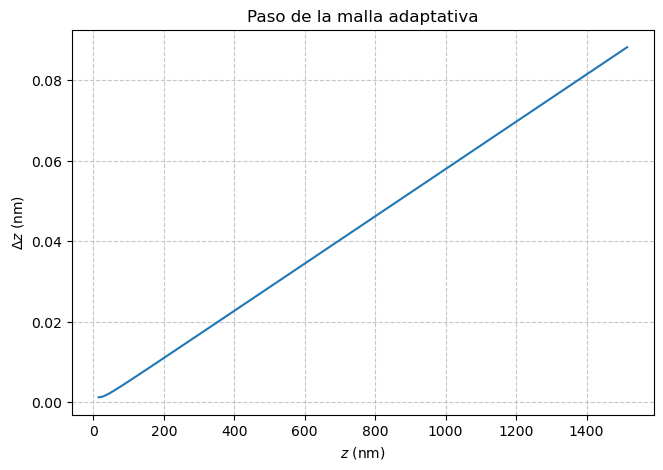

In [3]:
##############################################################################
# 2. Generación de la malla en z (nm)
##############################################################################

j_vals = np.arange(N_z)
z=d+L* np.sinh(alpha_grid * j_vals / (N_z - 1)) / np.sinh(alpha_grid)

plt.figure(figsize=(7.5,5))
plt.plot(z[1:],np.diff(z))
plt.xlabel(r"$z$ (nm)")
plt.ylabel(r"$\Delta z$ (nm)")
plt.title("Paso de la malla adaptativa")
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/Grid.pdf', bbox_inches='tight')
plt.show()
plt.close()

## Perfil de difusión
Para evitar discontinuidades en $D(z)$, se introduce una transición suave como los es $\tanh{}$, que es diferenciable y suave, lo que evita inestabilidades numéricas:

$$D(z)=D_0\left[\left(1-\exp{\left(-\lambda z\right)}\right)\cdot\left(1-S(z)\right)+S(z)\right],\quad S(z)=\frac{1}{2}\left(1+\tanh{\left(\frac{z-z_c}{\delta}\right)}\right)$$

Donde $z_c$ es la altura donde comienza la transición y $\delta$ es el ancho de la transición y se puede definir como $\delta\ll z_c$ para un cambio rápido pero suave. La transición suave refleja gradientes físicamente realistas.

In [4]:
##############################################################################
# 3. Función de Difusión Global D(z) (z en nm)
##############################################################################
def D(z_val):
    """Perfil de difusión completo con z en nm.
       D(z) = D0 [ex
        p(-λz)(1-S(z)) + S(z)] donde 
       S(z) = 0.5 [1 + tanh((z-z_c)/δ)].
    """
    S = 0.5 * (1 + np.tanh((z_val - (z_c+d)) / delta))
    # return D0 * ((1-np.exp(-lambda_param * z_val)) * (1 - S) + S)
    return D_s+(D0-D_s) * ((1-np.exp(-lambda_param * (z_val-d))) * (1 - S) + S)

En la figura a continuación se muestra el perfil propuesto utilizando algunos parámetros seleccionados de forma arbitraria.

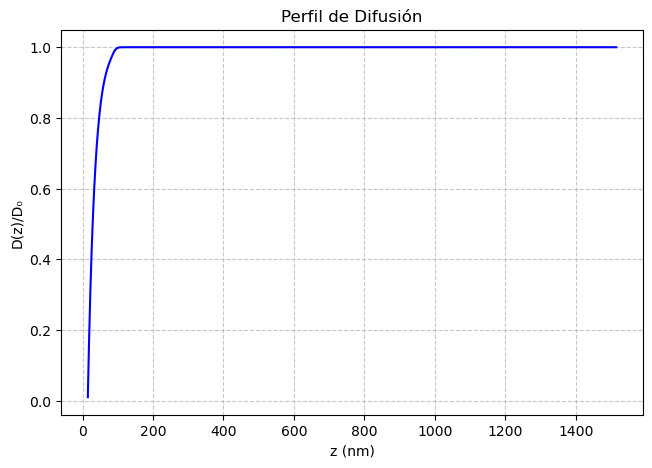

In [5]:
# Perfil de difusión
D_values = D(z)

plt.figure(figsize=(7.5,5))
plt.plot(z, D_values/D0, 'b-', lw=1.5)
plt.xlabel('z (nm)')
plt.ylabel('D(z)/D₀')
plt.title('Perfil de Difusión')
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/Dz_profile.pdf', bbox_inches='tight')
plt.show()
plt.close()

## Solución radial
l término radial se puede tomar constante también, para lo cual se toma $-\alpha^2$, de forma tal que:
    
$$\frac{1}{\rho \mathcal{R}}\left[\frac{d\mathcal{R}}{d\rho}+\rho\frac{d^2\mathcal{R}}{d\rho^2}\right]=-\alpha^2$$

Que al multiplicar por $\rho^2$ y simplificar, se obtiene una forma similar a la forma estándar de Bessel de orden cero:

$$\rho^2\frac{d^2\mathcal{R}}{d\rho^2}+\rho\frac{d\mathcal{R}}{d\rho}+\rho^2\alpha^2\mathcal{R}=0$$

Tomando un cambio de variable tal que $x=\alpha\rho$, $\frac{d\mathcal{R}}{d\rho}=\alpha\frac{d\mathcal{R}}{dx}$ y $\frac{d^2\mathcal{R}}{d\rho^2}=\alpha^2\frac{d^2\mathcal{R}}{dx^2}$, al reemplazar en la ecuación original:

$$\frac{x^2}{\alpha^2}\alpha^2\frac{d^2\mathcal{R}}{dx^2}+\frac{x}{\alpha}\alpha\frac{d\mathcal{R}}{dx}+\frac{x^2}{\alpha^2}\alpha^2\mathcal{R}=0$$

Lo que nos lleva a la forma estándar de Bessel de orden cero:

$$x^2\frac{d^2\mathcal{R}}{dx^2}+x\frac{d\mathcal{R}}{dx}+x^2\mathcal{R}=0$$

Esta ecuación tiene como solución una combinación de funciones de Bessel de primera y segunda categoría:

$$\mathcal{R}(x)=AJ_0(x)+BY_0(x)$$

Debido a que $Y_0(x)$ presenta una singularidad cuando $x\to0$, se toma que $B=0$, por lo que la solución estaría dada como:

$$\mathcal{R}(\rho)=AJ_0(\alpha\rho)$$

Al aplicar las condiciones de frontera $\mathcal{R}(\rho=R)=0$:

$$\mathcal{R}(R)=AJ_0(\alpha R)=0$$

En la función de Bessel de primera especie, los ceros están dados como $j_{0,n}$, por lo que se tendría que $\alpha_n=\frac{j_{0,n}}{R}$, lo que nos lleva a una serie en la cual cada modo $n$ corresponde a un valor propio $\alpha_n$:

$$\mathcal{R}_n(\rho)=A_nJ_0\left(\frac{j_{0,n}}{R}\rho\right)$$

De tal forma que la solución para la parte radial está dada por la serie de Fourier-Bessel de la ecuación:

$$\mathcal{R}(\rho)=\sum_{n=1}^\infty A_nJ_0\left(\frac{j_{0,n}}{R}\rho\right)$$

El $A_n$ se integrará con los valores de $T_0$ de la solución temporal y los coeficientes de expansión axiales.

In [6]:
##############################################################################
# 4. Solución Radial R(ρ)
##############################################################################

# Promedio armónico de 1/D(z) en [0, L]
integral_D = np.trapz(1/D_values,z)
D_eff = L / integral_D
D_eff

1884928.7900032925

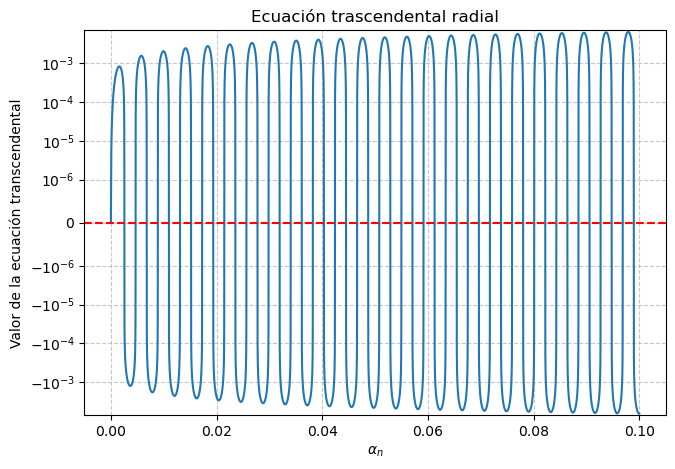

In [7]:
# Solución de la ecuación trascendental

def robin_eq(alpha):
    return alpha * jv(1, alpha * R) - (varkappa / D_eff) * jv(0, alpha * R)

plt.figure(figsize=(7.5,5))
alpha_plot=np.linspace(0,0.1,N_r)
plt.plot(alpha_plot,robin_eq(alpha_plot))
# plt.legend()
plt.title("Ecuación trascendental radial")
plt.ylabel("Valor de la ecuación transcendental")
plt.xlabel(r"$\alpha_n$")
plt.axhline(0, color='red', linestyle='--')
plt.yscale('symlog', linthresh=1e-6)
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/transcendental_radial.pdf', bbox_inches='tight')
plt.show()

In [8]:
# Estimar raíces con brentq en intervalos [a, b] con cambio de signo
alpha_min = 0.0
alpha_roots = []
step = 0.0001  # Paso inicial para buscar raíces

alpha_current = alpha_min
while len(alpha_roots) < n_modes_radial:
    # Buscar raíces en el intervalo [Lambda_current, Lambda_current + step]
    try:
        root = brentq(robin_eq, alpha_current, alpha_current + step, xtol=1e-6)
        alpha_roots.append(root)
        alpha_current = root + step  # Mover el inicio para la próxima búsqueda
    except ValueError:
        alpha_current += step
alpha_n=np.array(alpha_roots)

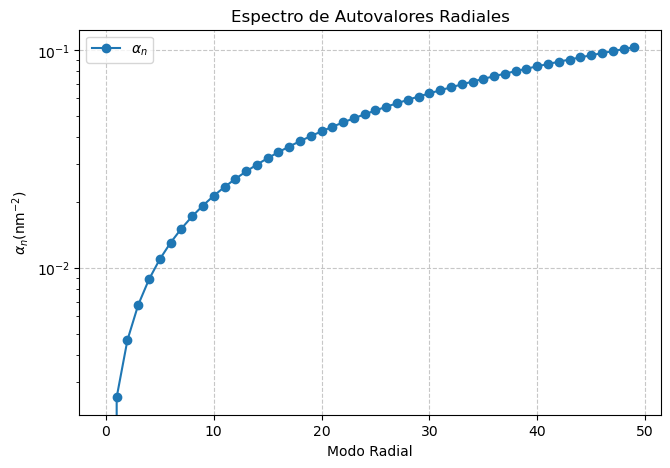

In [9]:
plt.figure(figsize=(7.5, 5))
plt.semilogy(alpha_n, 'o-', label=r"$\alpha_n$")
plt.xlabel('Modo Radial')
plt.ylabel(r'$\alpha_n (\text{nm}^{-2})$')
plt.title('Espectro de Autovalores Radiales')
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/alpha_n.pdf', bbox_inches='tight')
plt.show()
plt.close()

In [10]:
def R_func(alpha, rho):
    """
    Calcula R_n(rho) = J0(alpha_n * rho) normalizados con la norma analítica
      ∫₀ᴿ J₀²(αₙ ρ) ρ dρ = (R²/2)[J₀²(αₙR) + J₁²(αₙR)].

    Args:
        alpha_n: array de raíces αₙ, shape (n_modes,)
        rho_vals: escalar o array de posiciones radiales, shape (m,)

    Returns:
        R_normed: array (n_modes, m) de los modos normalizados
        norms:    array (n_modes,) con el valor exacto de la norma
    """
   # 1) Aseguramos que alpha_n y rho_vals sean arrays 1D
    alpha_arr = np.atleast_1d(alpha)              # shape (n_modes,)
    rho_arr   = np.atleast_1d(rho)             # shape (m,)

    # 2) Creamos vistas 2D para broadcasting
    alpha = alpha_arr.reshape(-1, 1)                # (n_modes, 1)
    rho   = rho_arr.reshape(1, -1)                  # (1, m)

    # 3) Evaluamos el modo sin normalizar
    R_matrix = jv(0, alpha * rho)                   # (n_modes, m)

    # 4) Calculamos la norma analítica usando alpha_arr (no el escalar viejo)
    J0R = jv(0, alpha_arr * R)                      # (n_modes,)
    J1R = jv(1, alpha_arr * R)                    # (n_modes,)
    norms = 0.5 * R**2 * (J0R**2 + J1R**2)           # (n_modes,)

    # 5) Aseguramos que norms sea un array 1D
    norms = np.atleast_1d(norms)

    # 6) Factor de normalización
    N = 1.0 / np.sqrt(norms)                        # (n_modes,)

    # 7) Aplicamos normalización por filas
    R_normed = N[:, None] * R_matrix                # (n_modes, m)

    return R_normed, np.sqrt(norms)

C:\Users\AllanGonzalez\AppData\Local\Temp\ipykernel_7000\2847836915.py:14: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("figuras/modos_radiales.pdf", bbox_inches="tight")
C:\Users\AllanGonzalez\AppData\Local\Temp\ipykernel_7000\2847836915.py:14: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("figuras/modos_radiales.pdf", bbox_inches="tight")
C:\Users\AllanGonzalez\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


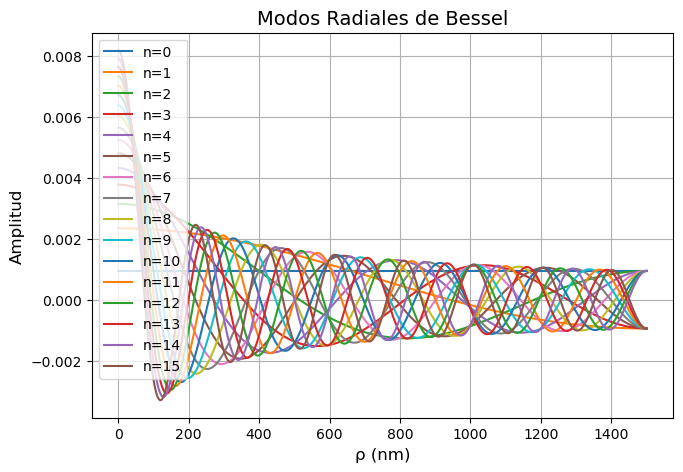

In [11]:
rho_vals = np.linspace(0.0, R, N_r)
R_values,R_norms=R_func(alpha_n,rho_vals)

# Graficar modos radiales
plt.figure(figsize=(7.5, 5))
for n in range(min(16, n_modes_radial)):
    plt.plot(rho_vals, R_values[n], label=f"n={n}", linewidth=1.5)

plt.xlabel("ρ (nm)", fontsize=12)
plt.ylabel("Amplitud", fontsize=12)
plt.title("Modos Radiales de Bessel", fontsize=14)
plt.legend()
plt.grid(True)
plt.savefig("figuras/modos_radiales.pdf", bbox_inches="tight")
plt.show()
plt.close()

## Solución axial

En el caso del término axial se puede discretizar utilizando una diferencia hacia adelante para la primera derivada de $Z$:

$$\left.\frac{dZ}{dz}\right\vert_{z_j}\approx\frac{Z_{j+1}-Z_j}{h_{j+1}}$$

Mientras que para la segunda derivada:

$$\left.\frac{d}{dz}\left(D(z)\frac{dZ}{dz}\right)\right\vert_{z_j}\approx\frac{D_{j+\frac{1}{2}}\frac{Z_{j+1}+Z_j}{h_{j+1}}-D_{j-\frac{1}{2}}\frac{Z_j-Z_{j-1}}{h_j}}{h_{j+\frac{1}{2}}}$$

Donde $D_{j+\frac{1}{2}}=\frac{D(z_{j+1})-D(z_j)}{2}$. De esta forma la ecuación discretizada para los nodos internos, luego de sustituir y simplificar queda como:

$$\frac{D_{j+\frac{1}{2}}\left(Z_{j+1}-Z_j\right)}{h_{j+1}^2}-\frac{D_{j-\frac{1}{2}}\left(Z_j-Z_{j-1}\right)}{h_j^2}+\left(\Lambda^2-\alpha^2D_j\right)Z_j=0,\,\forall\,j=1,2,\dots,N_z-2$$
            
### Condiciones de contorno

#### Superficie ($z=0,\,j=0$)

En la superficie tenemos la condición de Robin, por lo que se puede proceder aproximando la derivada en $j=0$:

$$\left.\frac{dZ}{dz}\right\vert_{z_0}\approx\frac{Z_1-Z_{-1}}{2h_1}$$

Por lo que sustituyendo:

$$D_0\frac{Z_1-Z_{-1}}{2h_0}+\kappa Z_0=0\Rightarrow Z_{-1}=Z_1+\frac{2h_0\kappa}{D_0}Z_0$$

#### Borde superior $(z=L,\,j=N_z-1)$

En el borde superior tenemos una condición de Neumann de la ecuación, que al ser aproximada en $j=N_z-1$ queda de la forma:

$$\left.\frac{dZ}{dz}\right\vert_{z_{N_z-1}}\approx \frac{Z_{N_z-1}-Z_{N_z-2}}{h_{N_z-1}}$$

Y al sustituir en la condición:

$$\frac{Z_{N_z-1}-Z_{N_z-2}}{h_{N_z-1}}=0\Rightarrow Z_{N_z-1}=Z_{N_z-2}$$

### Ensamblaje de la matriz del sistema}

El sistema $AZ=\Lambda^2Z$ es un sistema de matriz tridiagonal y simétrica, se puede observar tras desarrollar y agrupar los productos de la ecuación:

$$-\frac{D_{j+\frac{1}{2}}}{h_j^2}Z_{j+1}+\left(\frac{D_{j-\frac{1}{2}}}{h_{j-1}^2}+\frac{D_{j+\frac{1}{2}}}{h_j^2}+\alpha^2D_j\right)Z_j-\frac{D_{j-\frac{1}{2}}}{h_{j-1}^2}Z_{j-1}=\Lambda^2Z_j$$
            
La matriz, al tratarse de un problema de Sturm-Liouville, debe ser simétrica:
$$
A=
\begin{pmatrix}
    a_0 & b_0 & 0 & \dots & 0 \\
    b_1 & a_1 & b_1 & \dots & 0 \\
    0 & \ddots & \ddots & \ddots & 0 \\
    0 & \dots & b_{N_z-2} & a_{N_z-2} & b_{N_z-2} \\
    0 & \dots & 0 & b_{N_z-1} & a_{N_z-1} \\
\end{pmatrix}
$$

Las diagonales estarán construidas como:

$$a_j=\frac{D_{j-\frac{1}{2}}}{h_{j-1}^2}+\frac{D_{j+\frac{1}{2}}}{h_j^2}+\alpha^2D_j$$

y 

$$b_j=-\frac{D_{j+\frac{1}{2}}}{h_j^2}$$

La diagonal principal contiene el término $\alpha^2D_j$, lo cual incorpora al modo radial dentro de la diagonal, lo que permite que los autovalores calculados no sean solamente los $\beta_m$, sino que más bien los $\Lambda_{n,m}$, de igual forma se incluye en la condición de contorno para $z=0$, como se observa en:

$$a_0 = \frac{2D_0}{h_0^2} - \frac{2\kappa}{h_0} + \alpha^2 D_0,\quad b_0 = -\frac{2D_0}{h_0^2}$$
            
Y las condiciones de Neumann quedan como:

$$a_{N_z-1} = \frac{D_L}{h_L^2} + \alpha^2 D_L,\quad b_{N_z-2} = -\frac{D_L}{h_L^2}$$

In [12]:
##############################################################################
# 5. Solución Axial Z(z)
##############################################################################
def build_system(n):
    """
    Construye la matriz simétrica A para el modo radial n.
    
    Args:
        n (int): Índice del modo radial.
        
    Returns:
        A (csr_matrix): Matriz simétrica tridiagonal.
    """
    try:
        alpha = alpha_n[n]
        h = np.diff(z)
        N = len(z)
        main_diag = np.zeros(N)
        upper_diag = np.zeros(N-1)
        lower_diag = np.zeros(N-1)

        # ---------------------------------------------------------------
        # 1. Índices internos (j=1 a N-2)
        # ---------------------------------------------------------------
        j_int = np.arange(1, N-1)  # j=1, 2, ..., N-2
        j_prev = j_int - 1         # j-1 = 0, 1, ..., N-3
        j_next = j_int + 1         # j+1 = 2, 3, ..., N-1
    
        # ---------------------------------------------------------------
        # 2. Cálculo de coeficientes (vectorizado)
        # ---------------------------------------------------------------
        # Promedios armónicos de D en interfases
        D_prev = 2*D_values[j_int]*D_values[j_prev]/(D_values[j_int] + D_values[j_prev])  # D_{j-1/2}
        D_next = 2*D_values[j_int]*D_values[j_next]/(D_values[j_int] + D_values[j_next])  # D_{j+1/2}
        
        # Espaciados promedio
        h_m  = h[j_prev]                 # h_{j-1/2}
        h_p  = h[j_int]                  # h_{j+1/2}
        h_j  = 0.5 * (h_m + h_p)         # h_j
    
        # Términos de la matriz (simétricos)
        main_diag[j_int] = (
              D_prev / (h_m * h_j)    # coeficiente de Z_{j-1}
            + D_next / (h_p * h_j)    # coeficiente de Z_{j+1}
            + alpha**2 * D_values[j_int]
        )
        lower_diag[j_prev] = - D_prev / (h_m * h_j)      # A[j, j-1]
        upper_diag[j_int]  = - D_next / (h_p * h_j)      # A[j, j+1]
    
        # ---------------------------------------------------------------
        # 3. Condiciones de contorno - Simétricas
        # ---------------------------------------------------------------
        # Robin en z=0: D·Z' - κ·Z = 0  ⇒  a₀ = 2D₀/h₀² + 2κ/h₀ + α²D₀,  b₀ = -2D₀/h₀²

        D_1_2 = 2 * D_values[0] * D_values[1] / (D_values[0] + D_values[1])  # armónico
        h_1_2 = h[0]  # ya que h[0] = z[1] - z[0]
        h0 = h[0]
        D0 = D_values[0]
        main_diag[0]   =  D_1_2/h0/h_1_2+D0/h0**2   + 2*varkappa/h0   + alpha**2*D0
        upper_diag[0]  = -D_1_2/h0/h_1_2-D0/h0**2
        lower_diag[0]  =  upper_diag[0]   # A[1,0] = A[0,1]
        
        # Robin en z=L: D·Z' + κ·Z = 0  ⇒  a_{N-1} = D_L/h_L² + κ/h_L + α²D_L,  b_{N-2} = -D_L/h_L²
        D_3_2 = 2 * D_values[-1] * D_values[-2] / (D_values[-1] + D_values[-2])
        hL = h[-1]
        h_3_2 = h[-2]
        DL = D_values[-1]
        main_diag[-1]   =  DL/hL**2 + D_3_2/h_3_2/hL  +  2*varkappa/hL   + alpha**2*DL
        lower_diag[-2]  = -D_3_2/hL/h_3_2-DL/hL**2
        upper_diag[-1]  =  lower_diag[-2]  # A[N-2,N-1] = A[N-1,N-2]
    
        # ---------------------------------------------------------------
        # 4. Ensamblar matriz tridiagonal simétrica
        # ---------------------------------------------------------------
        A = diags(
            diagonals=[main_diag, upper_diag, lower_diag],
            offsets=[0, 1, -1],
            shape=(N, N),
            format='csr'
        ) # + 1e-10 * identity(N)
        eigenvalues, eigenvectors = eigsh(A, k=m_max, sigma=0.0, which='LA', tol=1e-6, maxiter=10000)
        # eigvals, eigvecs = eigh_tridiagonal(main_diag, upper_diag, select='i',select_range=(0, m_max-1))
        # eigenvalues, eigenvectors = eigh_tridiagonal(main_diag, upper_diag, select='i', select_range=(0, m_max-1),eigvals_only=False)
        return (n, (eigenvalues, eigenvectors))
    except ArpackNoConvergence:
        print(f"Advertencia: Modo axial para n={n} no convergió. Usando ceros.")
        return (n, (np.zeros(m_max), np.zeros((N, m_max))))

axial_results = Parallel(n_jobs=4, verbose=1)(delayed(build_system)(n) for n in range(n_modes_radial))
eigenvalues_ax = {}
eigenvectors_ax = {}
for n, (evals, evecs) in sorted(axial_results, key=lambda x: x[0]):
    eigenvalues_ax[n] = evals
    eigenvectors_ax[n] = evecs

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   55.6s
[Parallel(n_jobs=4)]: Done  50 out of  50 | elapsed:  1.1min finished


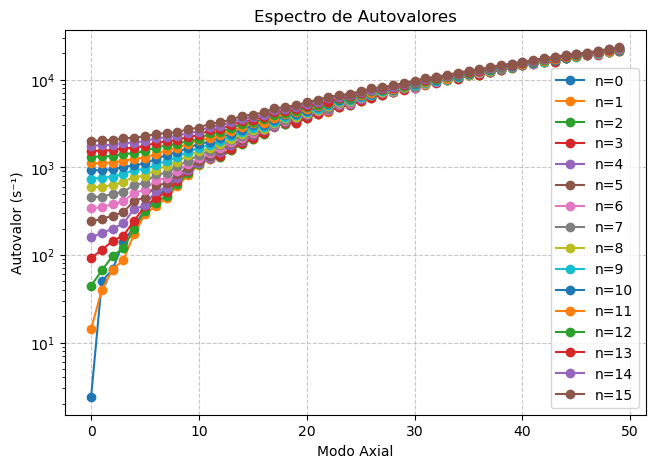

In [13]:
# Graficar espectro de autovalores
plt.figure(figsize=(7.5,5))
for n in range(min(16,n_modes_radial)):
    evals = eigenvalues_ax[n]
    plt.semilogy(evals, 'o-', label=f'n={n}')
plt.xlabel('Modo Axial')
plt.ylabel('Autovalor (s⁻¹)')
plt.title('Espectro de Autovalores')
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/eigenvalues.pdf', bbox_inches='tight')
plt.show()
plt.close()

In [14]:
eigenvalues_ax = np.array([
    [eigenvalues_ax[n][m] for m in range(m_max)]
    for n in range(n_modes_radial)
])
eigenvectors_ax = np.array([
    [eigenvectors_ax[n][:,m] for m in range(m_max)]
    for n in range(n_modes_radial)
])

In [15]:
#  # Normalizar los modos axiales en z

# 1. Cálculo de normas vectorizado
#    norms[n, m] = sqrt( ∫ eigenvectors_arr[n,m,:]^2 dz )
norms = np.sqrt(np.trapz(eigenvectors_ax.astype(np.float32)**2, z, axis=2))  # shape (n_modes_radial, m_max)

# 2. Normalizar cada vector [n,m,:] de forma broadcasting
#    eigenvectors_arr[n, m, :] /= norms_safe[n, m]
eigenvectors_ax /= norms[:, :, None]

C:\Users\AllanGonzalez\AppData\Local\Temp\ipykernel_7000\2445860930.py:11: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("figuras/modos_axiales.pdf", bbox_inches="tight")
C:\Users\AllanGonzalez\AppData\Local\Temp\ipykernel_7000\2445860930.py:11: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("figuras/modos_axiales.pdf", bbox_inches="tight")
C:\Users\AllanGonzalez\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


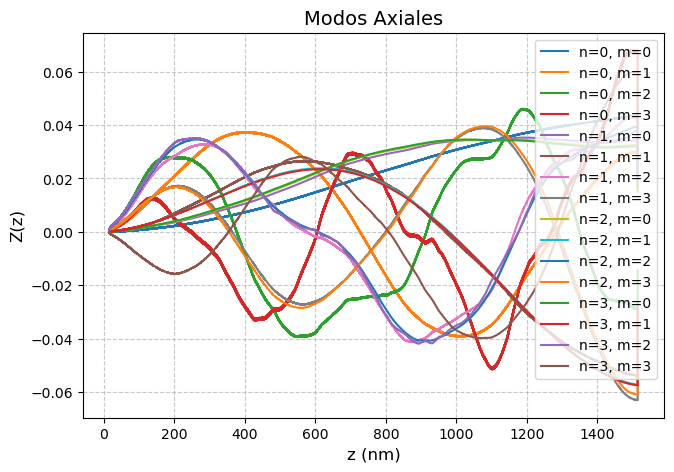

In [16]:
# Graficar algunos modos axiales
plt.figure(figsize=(7.5,5))
for n in range(4): # range(min(3, n_modes_radial)):
    for m in range(4):
        plt.plot(z, eigenvectors_ax[n][m,:], label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel("z (nm)", fontsize=12)
plt.ylabel("Z(z)", fontsize=12)
plt.title("Modos Axiales", fontsize=14)
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig("figuras/modos_axiales.pdf", bbox_inches="tight")
plt.show()
plt.close()

## Solución temporal

Se tiene que este debe ser constante, por lo que se toma $-\Lambda^2$, lo que permite plantear la ecuación:
    
$$\frac{1}{T}\frac{dT}{dt}=-\Lambda^2$$

De forma que al resolver la ecuación, se obtiene la solución:

$$T=\sum_{n=1}^{N_\rho}\sum_{m=1}^{M_z}T_{n,m}\exp{\left(-\Lambda_{n,m}^2t\right)}$$

Donde $\Lambda^2$ es un autovalor compuesto.

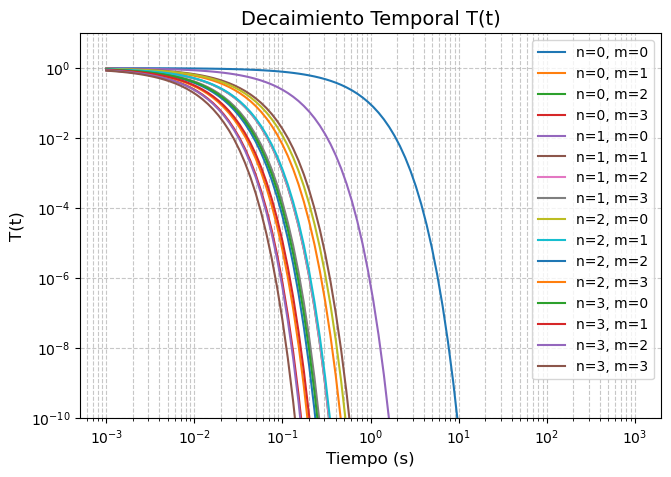

In [17]:
##############################################################################
### # 6. Término Temporal T(t)
##############################################################################
# Ahora, para cada eigenvalor (de la parte axial) usaremos el valor absoluto
# para que T(t)=exp(-|λ| t) decaiga.
def T(t, lam):
    return np.exp(-np.abs(lam) * t)

# Graficamos T(t) para los modos del sistema axial
plt.figure(figsize=(7.5,5))
t_plot = np.logspace(-3, 3, 100)
for n in range(min(4,n_modes_radial)):
    for m in range(min(4, m_max)):
        lam = eigenvalues_ax[n][m]
        plt.loglog(t_plot, T(t_plot, lam), label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel("Tiempo (s)", fontsize=12)
plt.ylabel("T(t)", fontsize=12)
plt.ylim(1e-10,1e1)
plt.title("Decaimiento Temporal T(t)", fontsize=14)
plt.legend()
plt.grid(ls='--', alpha=0.7, which="both")
plt.savefig("figuras/T_t.pdf", bbox_inches="tight")
plt.show()
plt.close()

## Cálculo de los coeficientes $A_{n,m}$

Los coeficientes de expansión $A_{n,m}$ se determinan a partir de la proyección de la condición inicial sobre las funciones $\mathcal{R}(\rho)$ y $Z(z)$, utilizando la ortogonalidad de las funciones propias:

$$\frac{\langle P(\rho,z,0),J_0(\alpha_n\rho)Z_{n,m}(z)\rangle}{\mathcal{N}_n\mathcal{M}_{n,m}}$$

Lo que nos da como resultado la expresión:

$$A_{n,m} = \frac{J_0(\alpha_n \rho_0) Z_{n,m}(z_0)}{2\pi\mathcal{N}_n \mathcal{M}_{n,m}}$$

Donde:
- **La norma radial:** se obtiene a partir de la ortogonalidad de las funciones de Bessel, como se muestra en: $$\mathcal{N}_n = \sqrt{\int_0^R \rho J_0^2(\alpha_n \rho) d\rho}=\sqrt{ \frac{R^2}{2} J_1^2(j_{0,n})}$$
- **La norma axial:** No es necesario ponderar pues la forma de la ecuación de Sturm-Liouville indica que $r(x)=1$. La integral se calcula utilizando el método del trapecio. $$\mathcal{M}_{n,m} = \sqrt{\int_0^L Z_{n,m}^2(z) dz}$$

In [18]:
# ##############################################################################
# # 7. Cálculo de Coeficientes A_{nm}
# ##############################################################################
# # Se asume que la condición inicial es:
# #     P(ρ, z, 0) ∝ δ(ρ-ρ0) δ(z-z0) / (2πρ0)
# # Con ρ0 = 750 nm y z0 = 10 nm.
# rho0 = 750  # nm
# z0 = 10    # nm

# --- Parámetros de la delta ---
rho0, z0 = R/2,  d+5.0  # centro (nm)

# --- 1) Mallado de cuadratura cilíndrica (ρ, z) ---
Nr_quad, Nz_quad = 300, 300
rho_quad = np.linspace(0.0, R, Nr_quad)   # nodos radiales
z_quad   = np.linspace(d, L+d, Nz_quad)   # nodos axiales

# (1) Evaluar modos radiales en rho0:
#     R_func(alpha_n, x) devuelve R_mat[n,i] = R_n(x)
#     Usamos un punto x = rho0
a0 = np.array([rho0])                       # array de un punto
R0, _ = R_func(alpha_n, a0)                # R0.shape = (n_modes_radial, 1)
R0 = R0[:, 0]                              # ahora vector (n_modes_radial,)

# (2) Construir splines axiales si no existen (z en nm)
#     Z_interps[n,m] interpola cada modo axial en [0, L]
Z_interps = np.empty((n_modes_radial, m_max), dtype=object)
for n in range(n_modes_radial):
    for m in range(m_max):
        Z_interps[n, m] = CubicSpline(z, eigenvectors_ax[n][m,:], extrapolate=False)

# (3) Evaluar modos axiales en z0
def eval_Z_at(z_val):
    Z0 = np.empty((n_modes_radial, m_max))
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z0[n, m] = Z_interps[n, m](z_val)
    return Z0

Z0 = eval_Z_at(z0)  # Z0.shape = (n_modes_radial, m_max)

# (4) Coeficientes modal A_nm: producto de R0 y Z0
#     A_nm_delta[n,m] = R_n(rho0) * Z_{n,m}(z0)
A_nm = R0[:, None] * Z0            # shape (n_modes_radial, m_max)
print(f"A_nm_delta shape: {A_nm.shape}")

A_nm_delta shape: (50, 50)


## Integración de la solución completa

La densidad de probabilidad final se reconstruye como superposición de todos los modos de las ecuaciones temporal y radial con la solución que se obtiene de forma numérica para la parte axial. De esta forma, se construye la solución de la ecuación inicial con coeficiente de difusión variable.

$$P(\rho,z,t) = \sum_{n=1}^{N_\rho} \sum_{m=1}^{M_z} A_{n,m} J_0(\alpha_n \rho) Z_{n,m}(z) e^{-\Lambda^2_{n,m} t},$$

donde $N_\rho$ y $M_z$ se eligen para garantizar convergencia.

In [19]:
##############################################################################
# 8. Densidad de Probabilidad P(ρ,z,t)
##############################################################################

rho_vals = np.linspace(0, R, 1000)
z_vals = np.linspace(d, L+d, 1000)

# precómputo fuera del loop de tiempo
Z_tens = np.stack([
    np.stack([Z_interps[n][m](z_vals) for m in range(m_max)], axis=1)
    for n in range(n_modes_radial)
], axis=1)  # shape (Nz, n_modes_radial, m_max)

In [20]:
R0_mat, _ = R_func(alpha_n, rho_vals)  # shape (n_modes_radial, Nr)

In [21]:
def compute_P_vec(t, Z_tens, R0_mat, A_nm):
    """
    Computa P(ρ,z,t) más rápido usando matrices precalculadas.

    Parámetros:
    - t: escalar de tiempo
    - Z_tens: shape (Nz, n_modes_radial, m_max)
    - R0_mat: shape (n_modes_radial, N_r)
    - A_nm: coeficientes modales (n_modes_radial, m_max)

    Devuelve:
    - P: shape (Nz, Nr)
    """
    T_decay = T(t, eigenvalues_ax)  # (n_modes, m_max)
    W = A_nm * T_decay               # (n_modes, m_max)
    B = np.sum(Z_tens * W[None, :, :], axis=2)  # (Nz, n_modes)
    S = np.dot(R0_mat.T, B.T)  # (Nr, Nz)
    return np.maximum(S.T, 0)

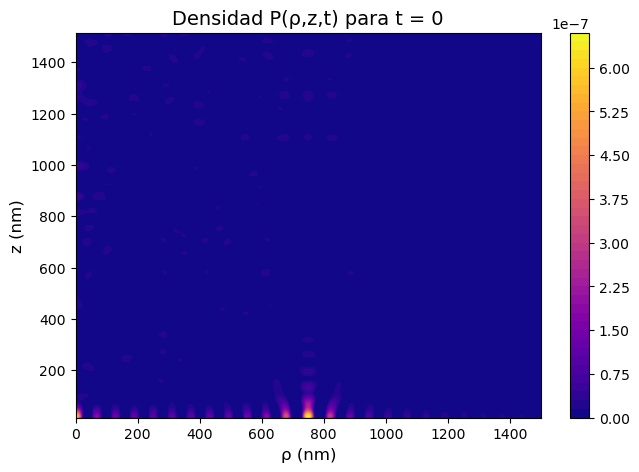

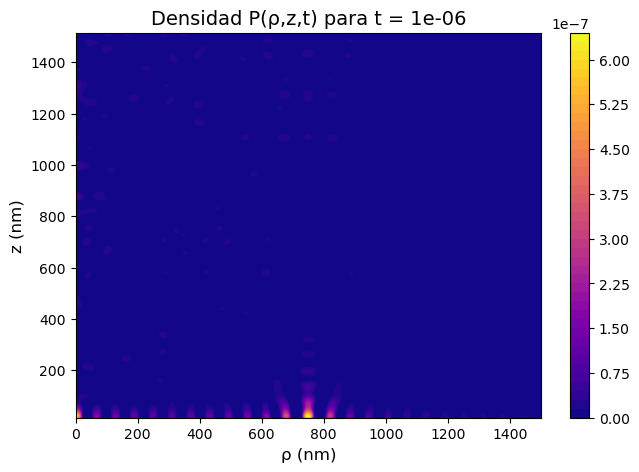

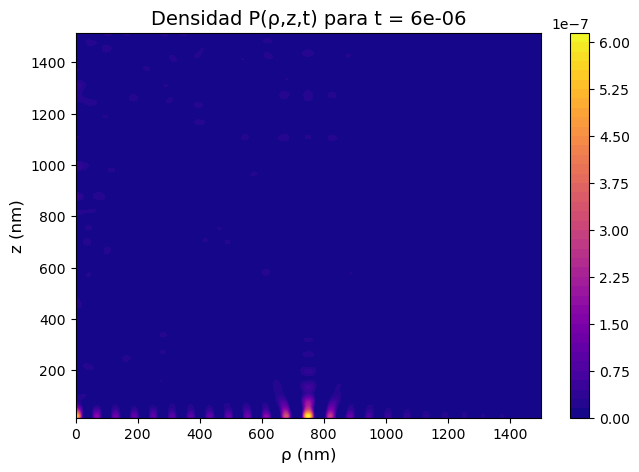

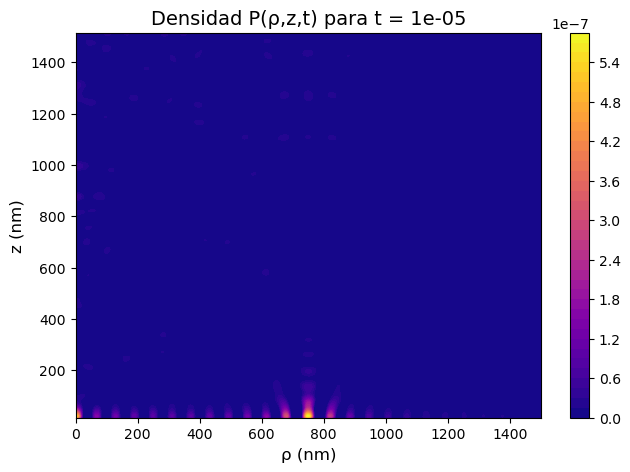

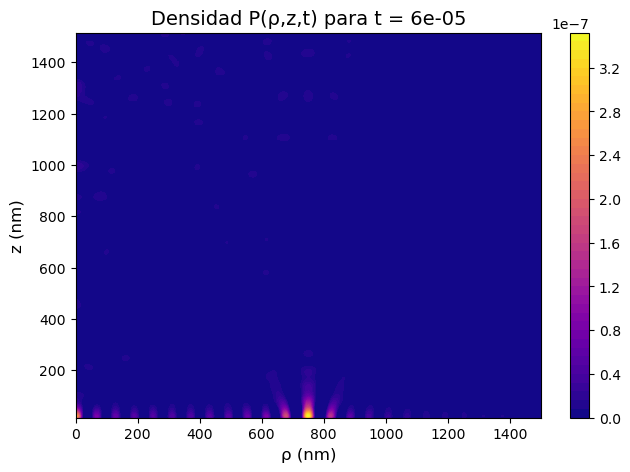

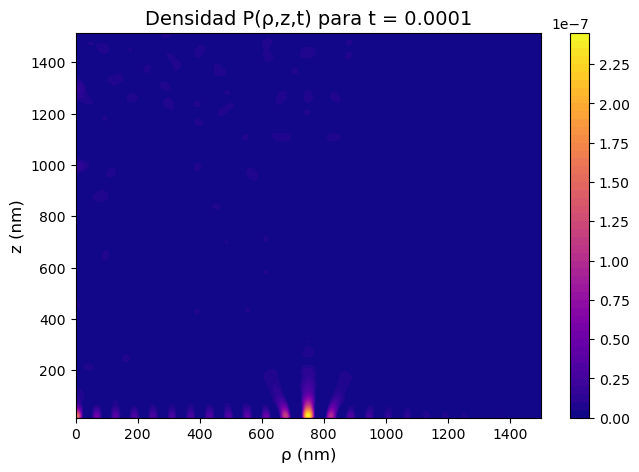

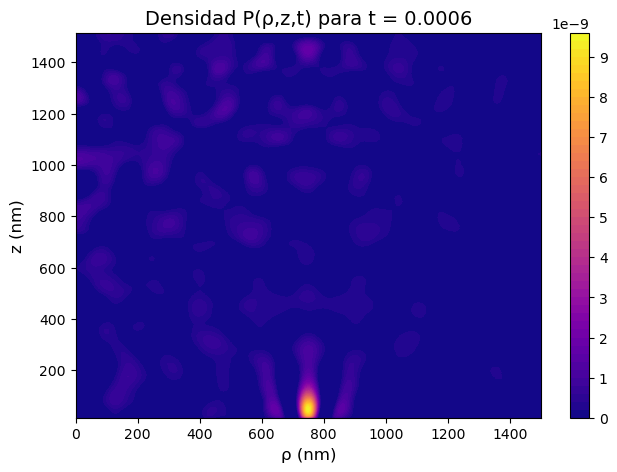

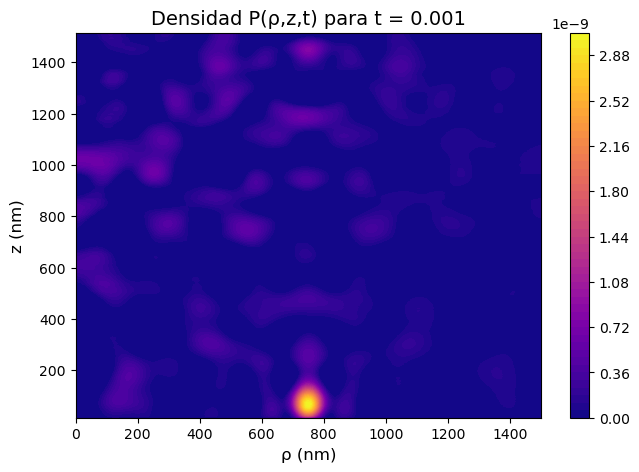

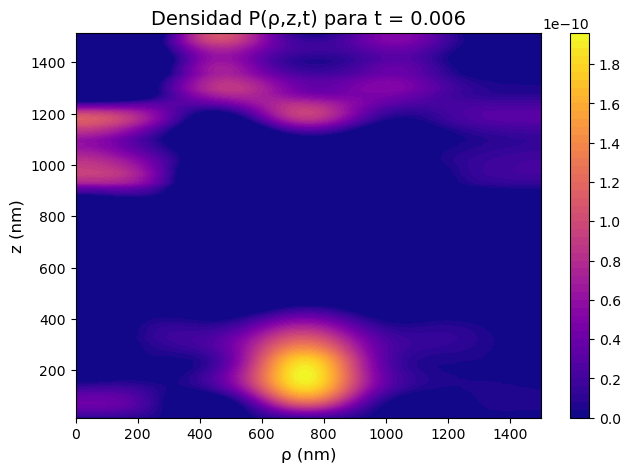

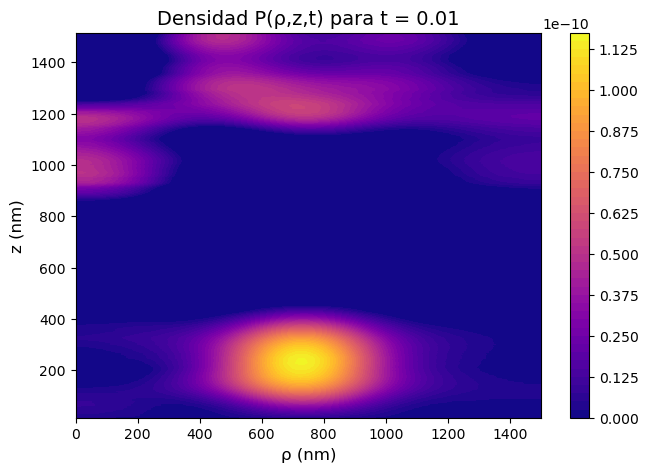

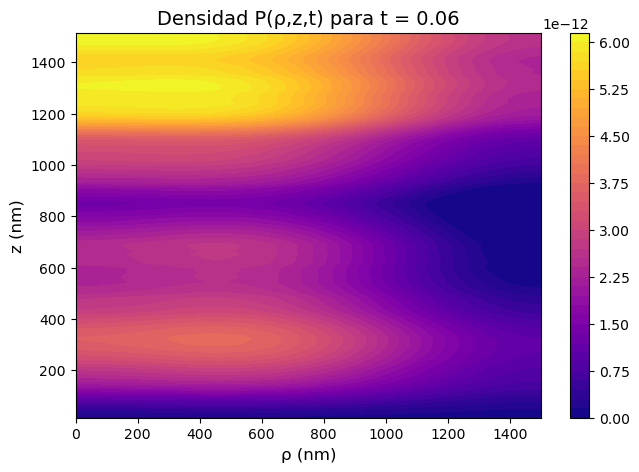

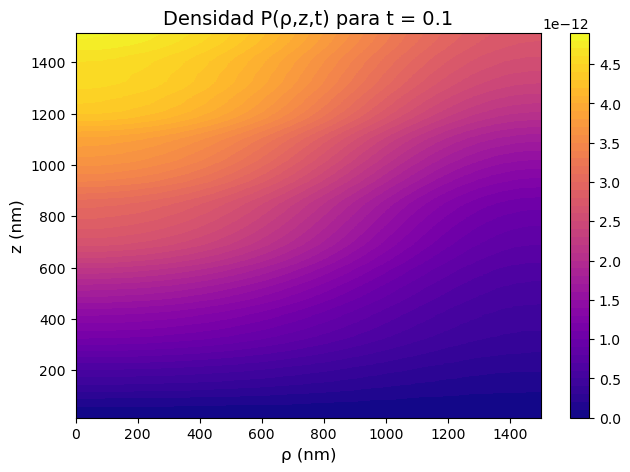

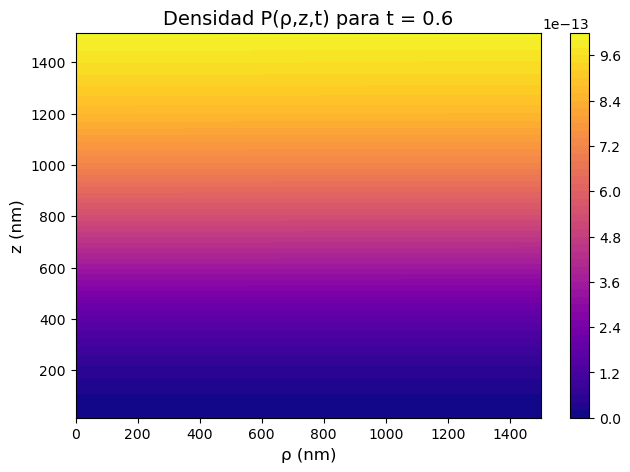

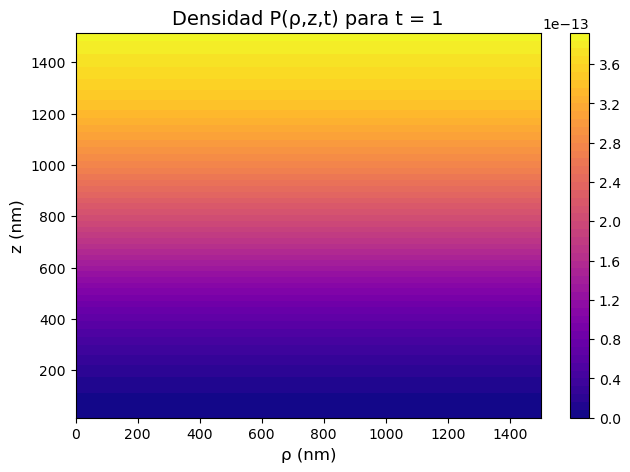

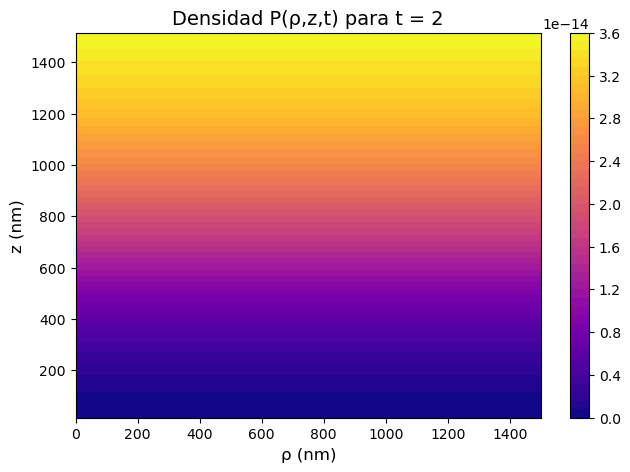

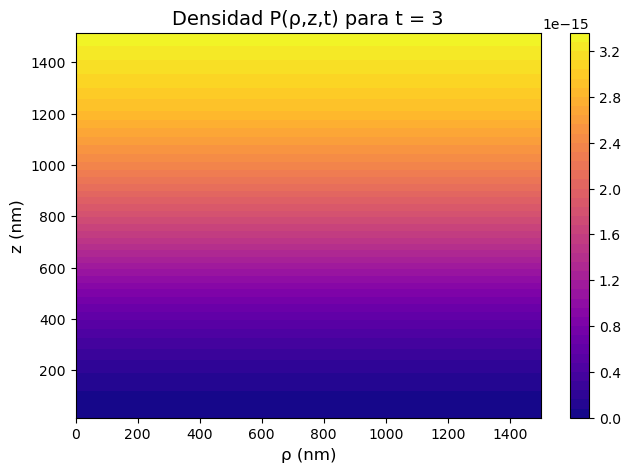

In [22]:
for t_val in [0,1e-6,6e-6,1e-5,6e-5,1e-4,6e-4,1e-3,6e-3,1e-2,6e-2,1e-1,6e-1,1,2,3]:
    P_val = compute_P_vec(t_val, Z_tens, R0_mat, A_nm)
    
    plt.figure(figsize=(7.5,5))
    plt.contourf(rho_vals, z_vals, P_val, 50, cmap="plasma")
    plt.xlabel("ρ (nm)", fontsize=12)
    plt.ylabel("z (nm)", fontsize=12)
    plt.title(f"Densidad P(ρ,z,t) para t = {t_val}", fontsize=14)
    plt.colorbar()
    plt.savefig(f"figuras/P_contour_{t_val}.pdf", bbox_inches="tight")
    plt.show()
    plt.close()

## Función de correlación $G(t)$
    
La función de correlación del campo magnético detectado por el sensor NV se define mediante:

$$G(t)=\langle B(t)B(0)\rangle\propto\int d^3\textbf{r}\int d^3\textbf{r}_0 f(\textbf{r})f(\textbf{r}_0)P(\textbf{r,t}\vert\textbf{r}_0,0)$$

donde el factor de forma dipolar

$$f(\textbf{r})\propto\frac{Y_2^0(\Omega)}{\rvert\textbf{r}\lvert^3}\quad\text{con}\quad Y_2^0(\theta)=\frac{1}{4}\sqrt{\frac{5}{\pi}}\left(\cos^2{\theta}-1\right)$$

refleja la dependencia angular y radial de la interacción dipolar, siendo $\cos{\theta}=\frac{z}{\sqrt{\rho^2+z^2}}$ y $P(\textbf{r},t\vert\textbf{r}_0,0)$ es el propagador de difusión con $D(z)$ variable.

Por lo tanto, la integral se reduce a la expresión:

$$G(t)\propto\int_0^R\rho d\rho\int_0^Ldz\int_0^R\rho_0d\rho_0\int_0^Ldz_0\frac{\left(3z^2-\rho^2\right)}{\left(\rho^2+z^2\right)^{\frac{5}{2}}}\frac{\left(3z_0^2-\rho_0^2\right)}{\left(\rho_0^2+z_0^2\right)^\frac{5}{2}}P(\rho,z,t\vert\rho_0,z_0,0)$$

### Cálculo de la Función de Correlación $G(t)$
    
En esta sección describimos el procedimiento numérico empleado para evaluar la integral y obtener la función de correlación espectral.

Partiendo de la definición y del propagador separable 

$$P(\rho,z,t|\rho_0,z_0,0)=\sum_{n,m}A_{n,m}\,J_0(\alpha_n\rho)\,Z_{n,m}(z)\,e^{-\Lambda_{n,m}^2t}$$

la integral cuádruple se reduce a sumas discretas en $\rho,\,z,\,\rho_0,\,z_0$ sobre nodos y pesos apropiados.

### Selección y discretización de subdominios

La señal principal proviene de $\rho\in[0.1R,0.9R]$, $z\in[7,13]\,\mathrm{nm}$. Se utilizan $N_q$ nodos en cada dirección con regla trapezoidal no uniforme en $z$ (mismo mallado adaptativo) y uniforme en $\rho$.

#### Coordenada radial $\rho$

Para la parte radial usamos un mallado uniforme

$$\rho_{i} = 0.1\,R + (i-1)\,\Delta\rho,\quad \Delta\rho = \frac{0.9\,R-0.1\,R}{N_{\rho}-1},\quad i=1,\dots,N_{\rho}$$

#### Coordenada axial $z$

Dado que $D(z)$ varía muy rápido cerca de la superficie y que la región de mayor interés para $G(t)$ está en $[7,13]\,\mathrm{nm}$ (alrededor de $z_c$), se muestrean $N_{z}^{\rm quad}$ puntos siguiendo el mismo mallado hiperbólico ya definido para la solución axial.

$$z_j\in\left[7,13\right]\,\mathrm{nm}\Rightarrow j\in\left[0,N_z^\mathrm{quad}\right]$$
     
**Pesos de integración (regla del trapecio no uniforme)**
Para el eje axial definimos los pesos según la regla del trapecio con espaciado no uniforme:

$$\Delta z_m = z_{\rm nodes}[m+1]-z_{\rm nodes}[m], 
\quad
\omega_{z,m}= 
\begin{cases}
    \dfrac{\Delta z_1}{2}, & m=1,\\[6pt]
    \dfrac{\Delta z_{m-1} + \Delta z_m}{2}, & 1<m<N_{z}^{\rm quad},\\[6pt]
    \dfrac{\Delta z_{N_{z}^{\rm quad}-1}}{2}, & m=N_{z}^{\rm quad}. 
\end{cases}$$

De esta manera preservamos la densidad variable de nodos en $z$ sin perder exactitud ni aumentar arbitrariamente la resolución en $\rho$.

### Algoritmo de cálculo de $G(t)$
                
Definimos la función $G(t)$ de forma discreta como:

$$G(t)=\frac{5}{16\pi}\sum_{i=1}^{N_{\rho}^\mathrm{quad}}\sum_{m=1}^{N_{z}^{\rm quad}}f(\rho_{i},z_\mathrm{nodes}[m]) P(\rho_{i},z_\mathrm{nodes}[m],t)\rho_i\Delta\rho w_{z,m}$$

Donde:

$$f(\rho,z)=\frac{3z^2-\rho^2}{(\rho^2+z^2)^{5/2}},\quad P(\rho,z,t)=\sum_{n=1}^{N_{\rm rad}}\sum_{m=1}^{M}A_{n,m}\,J_{0}\!(\alpha_{n}\rho)\,Z_{n,m}(z)\,e^{-\lambda_{n,m}t}$$

Y, además, $\{A_{n,m}\}$, $\{\alpha_n\}$, $\{Z_{n,p}\}$, $\{\Lambda_{n,m}\}$ provienen de las soluciones radial y axial.

In [23]:
##############################################################################
# 9. Función de Correlación G(t)
##############################################################################

# 1) nodos y pesos en z
N_quad=1000
# z_min, z_max = 0.0, L
# j = np.linspace(0, N_quad-1, N_quad)
# z_nodes = z_min + (z_max - z_min) * np.sinh(alpha_grid * j / (N_quad - 1)) / np.sinh(alpha_grid)
# dz = np.diff(z_nodes)
# wz = np.empty(N_quad)
# wz[0], wz[-1] = dz[0]/2, dz[-1]/2
# wz[1:-1] = 0.5*(dz[:-1] + dz[1:])

z_nodes=np.linspace(d,L+d,N_quad)
dz=z_nodes[1]-z_nodes[0]

# 2) nodos uniformes en rho
rho_nodes = np.linspace(0.0, R, N_quad)

# 3) matriz J0 para todos los modos y rho
R0_mat,_ = R_func(alpha_n, rho_nodes)   # (n_modes, Nr)

# 4) tensor axial Z(z_n) para todos los modos y sub-modos
Z_tens = np.empty((N_quad, n_modes_radial, m_max))
for n in range(n_modes_radial):
    for m in range(m_max):
        Z_tens[:, n, m] = Z_interps[n][m](z_nodes)

# 5) factor dipolar f(rho_i, z_j)
R2 = (rho_nodes)**2
Z2 = (z_nodes+1e-30)**2 # por el desplazamiento
f_mat = (3*Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5
f0=(3*z0**2-rho0**2)/(z0**2+rho0**2)**2.5 

# 6) dr
dr = rho_nodes[1]-rho_nodes[0]

t_values = np.logspace(-6, 0, N_quad)
tau_values=t_values*D_eff/d**2
# 7) Decaimiento temporal T_decay: (Nt, n_modes_radial, m_max)
T_decay = np.exp(
    - eigenvalues_ax[None, :, :]     # → (1, n_modes, m_max)
    * t_values[:, None, None]          # → (Nt, 1, 1)
)

# 8) Coeficientes combinados W: (Nt, n_modes_radial, m_max)
W = T_decay * A_nm[None, :, :]*f0

# 9) Colapso de modos axiales (m): B[t, z, n]
#    Z_tens: (Nz, n_modes_radial, m_max)
B = np.einsum('znm,tnm->tzn', Z_tens, W)   # → (Nt, Nz, n_modes_radial)

# 4) Colapso de modos radiales (n): S[t, r, z]
#    J0_mat: (n_modes_radial, Nr)
S = np.einsum('nr,tzn->trz', R0_mat, B)    # → (Nt, Nr, Nz)

# 5) Construcción del integrando y broadcasting limpio
#    S      : (Nt, Nr, Nz)
#    f_mat  : (Nr, Nz)         → f_mat[None, :, :]
#    rho    : (Nr,)            → rho[None, :, None]
#    wz     : (Nz,)            → wz[None, None, :]
integrand = (
    rho_nodes[None, :, None]   # (1, Nr, 1)
    * f_mat[None, :, :]      # (1, Nr, Nz)
    * S                        # (Nt, Nr, Nz)
    # * wz[None, None, :]        # (1, 1, Nz)
)

# 10) Integración final sobre rho y z
ints     = integrand.sum(axis=(1,2))*dr*dz  # → (Nt,)
G_values = (5/(16*np.pi)) * ints

np.savetxt("data/G_vs_t.dat", np.c_[t_values, G_values], header="Tiempo(s) G(t)", fmt="%.9e")

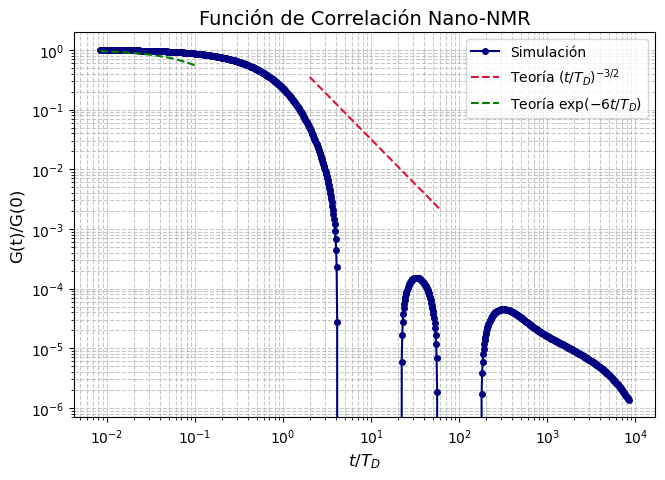

In [24]:
plt.figure(figsize=(7.5,5))
plt.loglog(tau_values, G_values/G_values[0], "o-", label="Simulación", color="navy", markersize=4, linewidth=1.5)
plt.plot(tau_values[(tau_values>=2)&(tau_values<=60)], tau_values[(tau_values>=2)&(tau_values<=60)]**-1.5, "--", label=r"Teoría $(t/T_D)^{-3/2}$", color="crimson", linewidth=1.5)
plt.plot(tau_values[tau_values<=0.1], np.exp(-6*tau_values[tau_values<=0.1]), "--", label=r"Teoría $\exp(-6t/T_D)$", color="green", linewidth=1.5)
# plt.xlabel("Tiempo (s)", fontsize=12)
plt.xlabel(r"$t/T_D$", fontsize=12)
plt.ylabel("G(t)/G(0)", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.grid(which="both", ls='--', alpha=0.7)
plt.savefig("figuras/correlacion_nanoNMR.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()